# Piece 7 — Controller and virtual sensors

* **Controller** (`core/control.py`): on/off with dead band, staged, inverter (PI); heating with its own dead band and a neutral zone so heating and cooling never fight; minimum on/off times; acts at discrete sample times on a **virtual sensor** reading (lag, calibration error, resolution, sampling), never on the true state.
* **Simulation**: solve_ivp between controller samples, restarted at every switching event.

> **Verification-only inputs.** The setpoint-curve points (E-110…E-115, *believed* 22 + 0.25·(T_out − 19) °C — **must be confirmed from EN 13129**), sensor properties, controller settings (verification unit card) and the coach are labelled stand-ins (`tests/data/verification_overrides.yaml`, `tests/data/verification_unit.yaml`). They show the machinery, not a real vehicle.

In [1]:
import sys, math
from pathlib import Path

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(root))

import numpy as np
import yaml
import matplotlib.pyplot as plt
from core import loads, psychro
from core.chamber import UnitTestRoom
from core.coach import LoadTerm, SingleZoneCoach, time_constant_s
from core.control import (ConstantCapacityPlant, Controller, ControlParams, ControlSensor,
                          FixedSetpoint, SetpointCurve, UnitPlant, simulate_controlled)
from core.sensors import SensorSet
from core.unit import DXUnit, UnitCard, load_unit_card
from evidence.registry import Registry

overrides = yaml.safe_load((root / "tests/data/verification_overrides.yaml").read_text())
curve_points = {"E-110": 19.0, "E-111": 22.0, "E-112": 35.0, "E-113": 26.0,
                "E-114": 45.0, "E-115": 28.5}                     # stand-ins, to confirm
reg = Registry().with_overrides({**overrides, **curve_points}, label="verification-only")
card = load_unit_card(root / "tests/data/verification_unit.yaml")
unit = DXUnit.from_card(card, evidence=reg)
coach = SingleZoneCoach("verification", 300.0, 1.2, 5e6, air_volume_m3=150.0)
setpoint = SetpointCurve.from_evidence(reg)
print("setpoint at 35 degC outside:", setpoint(35.0), "degC (stand-in curve)")

setpoint at 35 degC outside: 26.0 degC (stand-in curve)


## Same pull-down, three controller types

Coach soaked at 35 °C / 40 % RH outside, 80 passengers, DX verification unit, setpoint from the (stand-in) curve. The controller reads the return-air sensor with the stand-in PT100 properties (lag 10 s, ±0.1 K, 0.01 K resolution, 1 s sampling).

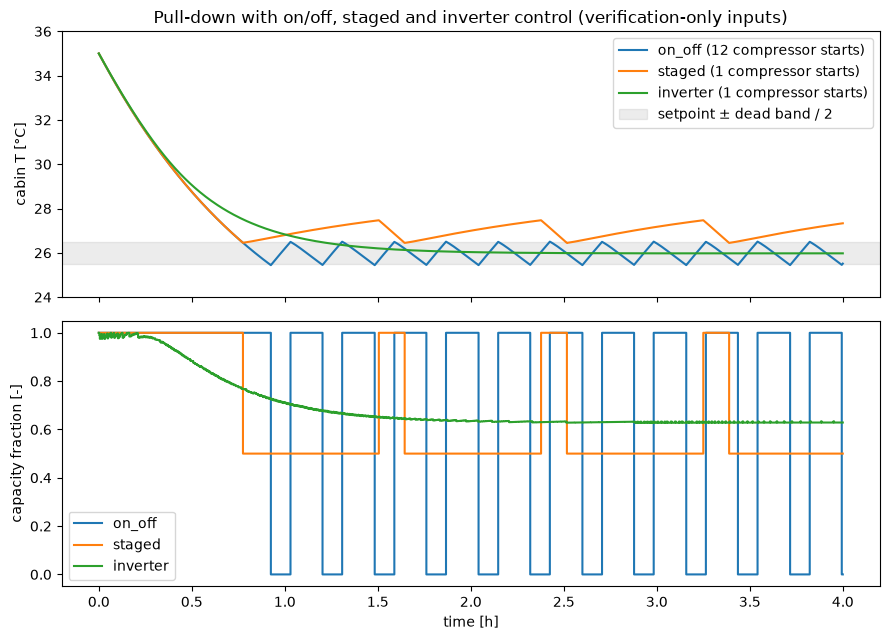

on_off   : starts  12, last hour cabin 25.45..26.51 degC
staged   : starts   1, last hour cabin 26.45..27.47 degC


inverter : starts   1, last hour cabin 25.98..25.98 degC


In [2]:
def controlled(ctype):
    data = card.model_dump(exclude_none=True)
    data["control_type"]["value"] = ctype
    p = ControlParams.from_card(UnitCard.model_validate(data))
    sensor = ControlSensor.from_sensors(SensorSet.from_evidence(reg, seed=0), p.sensor, reg)
    pax = LoadTerm("passengers", lambda t, T, W: loads.passengers(80, 70.0, 50.0, T_in=T))
    return simulate_controlled(coach, 35.0, 35.0, Controller(p), setpoint,
                               UnitPlant(unit, 0.40), sensor, 4 * 3600.0, 30.0,
                               W0=psychro.humidity_ratio(35.0, 0.40), loads=[pax])

runs = {c: controlled(c) for c in ("on_off", "staged", "inverter")}
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
for c, r in runs.items():
    d = r.data
    a1.plot(d["t_s"] / 3600, d["T_C"], label=f"{c} ({r.starts} compressor starts)")
    s = r.samples
    a2.step(s["t"] / 3600, s["fraction"].where(s["mode"] == "cooling", 0.0), where="post", label=c)
sp = setpoint(35.0)
a1.axhspan(sp - 0.5, sp + 0.5, color="grey", alpha=0.15, label="setpoint ± dead band / 2")
a1.set_ylabel("cabin T [°C]"); a1.legend(); a1.set_ylim(sp - 2, 36)
a2.set_ylabel("capacity fraction [-]"); a2.set_xlabel("time [h]"); a2.legend()
a1.set_title("Pull-down with on/off, staged and inverter control (verification-only inputs)")
plt.tight_layout(); plt.show()
for c, r in runs.items():
    last = r.data[r.data["t_s"] > 3 * 3600]
    print(f"{c:9s}: starts {r.starts:3d}, last hour cabin {last['T_C'].min():.2f}..{last['T_C'].max():.2f} degC")

## Analytic cycle-time check (verification mode)

Single zone, constant cooling capacity (no coil curve), ideal sensor without lag, 1 s controller sample. Each phase is an exponential approach to its steady state, so

$$t = \tau \ln\frac{T_{start} - T_{ss}}{T_{end} - T_{ss}},\qquad \tau = C/UA,$$

with $T_{ss}$ = 10 °C while cooling (12.6 kW at 45 °C outside) and 45 °C while off, between the thresholds 23 and 25 °C.

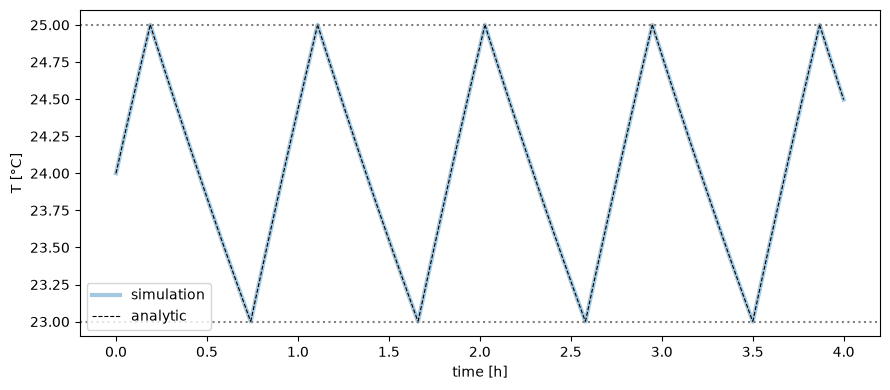

on : analytic  1987.5 s, simulated  1988.0 s (+0.025 %)
off: analytic  1323.8 s, simulated  1324.0 s (+0.019 %)


In [3]:
tau = time_constant_s(coach)
p = ControlParams("on_off", "return_air", 2.0, 1.0, 5.0, 0.0, 0.0, 1.0)
r = simulate_controlled(coach, 24.0, 45.0, Controller(p), FixedSetpoint(24.0),
                        ConstantCapacityPlant(12600.0), ControlSensor.ideal(), 4 * 3600, 20.0)
d = r.data
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(d["t_s"] / 3600, d["T_C"], lw=3, alpha=0.4, label="simulation")
# analytic: exponential from each switching event
T_now, t_prev = 24.0, 0.0
for k, seg in enumerate(r.segments):
    t = seg["t_s"].to_numpy()
    T_ss = 10.0 if seg["mode"].iloc[0] == "cooling" else 45.0
    T0 = seg["T_C"].iloc[0]
    ax.plot(t / 3600, T_ss + (T0 - T_ss) * np.exp(-(t - t[0]) / tau), "k--", lw=0.8,
            label="analytic" if k == 0 else None)
ax.axhline(25, color="grey", ls=":"); ax.axhline(23, color="grey", ls=":")
ax.set_xlabel("time [h]"); ax.set_ylabel("T [°C]"); ax.legend(); plt.tight_layout(); plt.show()

t_on = tau * math.log((25 - 10) / (23 - 10)); t_off = tau * math.log((23 - 45) / (25 - 45))
per = r.onoff_periods()
on = [b - a for s, a, b in per if s == "on"][1:]; off = [b - a for s, a, b in per if s == "off"][1:]
print(f"on : analytic {t_on:7.1f} s, simulated {np.mean(on):7.1f} s ({(np.mean(on)/t_on-1)*100:+.3f} %)")
print(f"off: analytic {t_off:7.1f} s, simulated {np.mean(off):7.1f} s ({(np.mean(off)/t_off-1)*100:+.3f} %)")

## Unit test room: RH sensors vs dew-point hygrometer

Air-enthalpy capacity at the rating point, measured with stand-in sensor accuracies: RH ±0.02 (E-059 stand-in) vs chilled-mirror dew point ±0.2 K (E-102 stand-in). The dew-point instrument measures the humidity ratio far more directly, which shrinks the capacity uncertainty.

rh       : 27.22 +/- 4.98 kW  (true 30.00 kW)
dew_point: 29.29 +/- 2.35 kW  (true 30.00 kW)


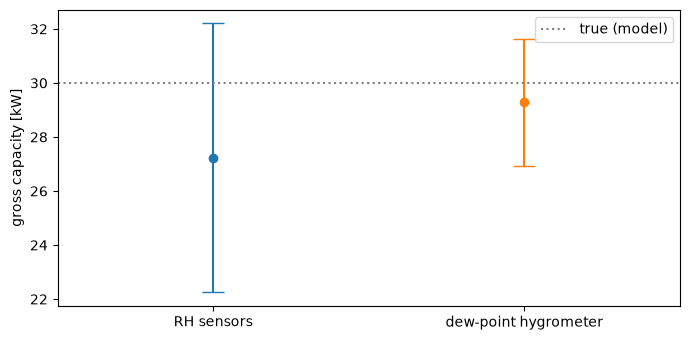

In [4]:
room = UnitTestRoom.from_evidence(reg)
indoor = (26.7, psychro.humidity_ratio_from_wet_bulb(26.7, 19.4))
outdoor = (35.0, psychro.humidity_ratio(35.0, 0.40))
res = {}
for hum in ("rh", "dew_point"):
    m = room.measure(unit, indoor, outdoor, "cooling", 1.0, 0.0,
                     SensorSet.from_evidence(reg, seed=0), humidity=hum)
    res[hum] = (m.measured["capacity_gross_W"], m.true["capacity_gross_W"])
fig, ax = plt.subplots(figsize=(7, 3.5))
for i, (hum, (g, true)) in enumerate(res.items()):
    ax.errorbar(i, g.value / 1e3, yerr=g.uncertainty / 1e3, fmt="o", capsize=8)
    print(f"{hum:9s}: {g.value/1e3:.2f} +/- {g.uncertainty/1e3:.2f} kW  (true {true/1e3:.2f} kW)")
ax.axhline(res["rh"][1] / 1e3, color="grey", ls=":", label="true (model)")
ax.set_xticks([0, 1], ["RH sensors", "dew-point hygrometer"]); ax.set_xlim(-0.5, 1.5)
ax.set_ylabel("gross capacity [kW]"); ax.legend(); plt.tight_layout(); plt.show()